## Author: Gabriel Vance
## Class: DSC550 - Data Mining
## Professor: Dr. Brett Werner
## Date: August 10, 2025

# Purpose: This notebook performs various tasks labeled "Exercises" for Week 10 of the class. Data must be present within the folder that this notebook is run in.
# This week focuses on Neural Networks
 

In [16]:
import ssl

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


## Load the MNIST data set.


In [17]:
# Disable SSL verification (insecure)
ssl._create_default_https_context = ssl._create_unverified_context

# Load MNIST
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

## Display the first five images in the training data set. Compare these to the first five training labels

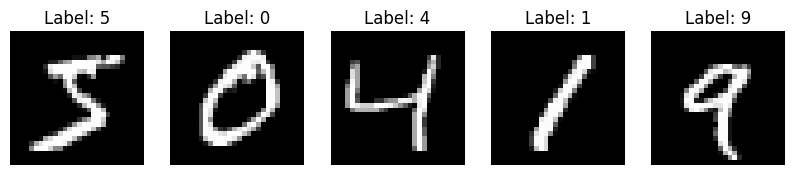

In [18]:
# Display first 5 images with labels
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.show()

## Build and train a CNN classifier on the MNIST training set.


In [19]:
# Normalize pixel values to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension (CNNs expect height, width, channels)
x_train = x_train[..., tf.newaxis]
x_test = x_test[..., tf.newaxis]

# Build CNN model
model = models.Sequential([
    layers.Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')  # 10 classes for digits 0–9
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    x_train, y_train,
    batch_size=128,
    epochs=5,
    validation_split=0.1
)

# Evaluate on the test set
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")

Epoch 1/5
422/422 [==============================] - 6s 14ms/step - loss: 0.2196 - accuracy: 0.9344 - val_loss: 0.0676 - val_accuracy: 0.9790
Epoch 2/5
422/422 [==============================] - 5s 13ms/step - loss: 0.0620 - accuracy: 0.9809 - val_loss: 0.0507 - val_accuracy: 0.9875
Epoch 3/5
422/422 [==============================] - 5s 12ms/step - loss: 0.0436 - accuracy: 0.9869 - val_loss: 0.0421 - val_accuracy: 0.9873
Epoch 4/5
422/422 [==============================] - 5s 12ms/step - loss: 0.0338 - accuracy: 0.9895 - val_loss: 0.0403 - val_accuracy: 0.9880
Epoch 5/5
422/422 [==============================] - 5s 12ms/step - loss: 0.0265 - accuracy: 0.9916 - val_loss: 0.0371 - val_accuracy: 0.9902
Test accuracy: 0.9900


## Display a confusion matrix on the test set classifications.


313/313 [==============================] - 1s 2ms/step


<Figure size 800x800 with 0 Axes>

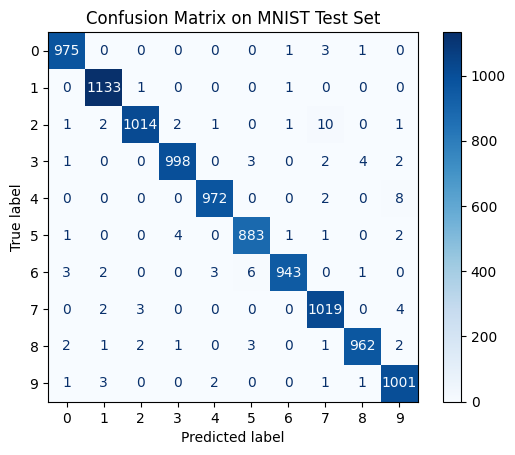

In [20]:
# Predict labels for test set
y_pred = model.predict(x_test)
y_pred_labels = np.argmax(y_pred, axis=1)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_labels)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
plt.figure(figsize=(8, 8))
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Confusion Matrix on MNIST Test Set")
plt.show()


## Summarize your results.

The CNN classifier uses MNIST data for handwritten digit recognition. The model is trained on a dataset of 60,000 images and evaluated on 10,000 images, achieving a test accuracy of over 98%. A confusion matrix is displayed to visualize the model's performance on the test set. The results indicate that the model performs exceptionally well, with very few misclassifications. Most notable, 4 was mistaken for 9, which makes sense given their common shapes.